In [7]:
import sys
import matplotlib.pyplot as plt
plt.rc("axes.spines", top=False, right=False)

import seaborn as sns
import pandas as pd
import numpy as np
from scipy import stats

from scipy.stats import norm
from scipy.optimize import curve_fit

from tqdm import tqdm

###changes default of autoreloader to continually reload (2) rather than only on restart
####good for debuggin but does slow code as it is continully reloading modules
%load_ext autoreload
%autoreload 2

###can also use dir() to check what is in function and that new params have been loaded

import os
import glob


#desktop = os.path.join(os.path.join(os.environ['USERPROFILE']), 'Desktop') 
plot_path="../output/plots"
mypath = plot_path
import sys
sys.path.append("../src")
from Branch_analysis import branch_dsc, update_DSCs, update_compartments
from Summary_analysis import summary_dsc, summary_compt, avgCDF
from plots import plot_dsc

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Load dendritic diameter data
sets the paths for each expeanded dendrite analysed

In [8]:
from pathlib import Path
DGdata={}

DGdata['dendrite1'] = {'path':'M:/Tony/Bonn/Data/Distal_Dendrite/Morphology/repo_data/ExM/2016_07_07/branch1/tables/2016_07_07_slice4_left_branch1_Local Diameter.csv'}
DGdata['dendrite1']['file']= '2016_07_07_slice4_left_branch1_Local Diameter.csv'
DGdata['dendrite1']['ex_factor'] = 4.1
DGdata['dendrite1']['res'] = 1

#sub-branch of branch 3 
# DGdata['branch2'] = {'path':''M:/Tony/Bonn/Data/Distal_Dendrite/Morphology/repo_data/ExM/2016_07_07/branch2/tables/2016_07_07_slice4_left_branch2_Local Diameter.csv'}
# DGdata['branch2']['file']= '2016_07_07_slice4_left_branch2_Local Diameter.csv'
# DGdata['branch2']['ex_factor'] = 4.1
# DGdata['branch2']['res'] = 1

DGdata['dendrite3'] = {'path':'M:/Tony/Bonn/Data/Distal_Dendrite/Morphology/repo_data/ExM/2016_07_07/branch3/tables/2016_07_07_slice4_left_branch3_Local Diameter.csv'}
DGdata['dendrite3']['file']= 'branch3_comp_localDiameter1.csv'
DGdata['dendrite3']['ex_factor'] = 4.1
DGdata['dendrite3']['res'] = 1

DGdata['dendrite4'] = {'path':'M:/Tony/Bonn/Data/Distal_Dendrite/Morphology/repo_data/ExM/2019_05_04/branch4/tables/2019_05_04_slice3_side1_branch4_localDiameter.csv'}
DGdata['dendrite4']['file']= '2019_05_04_slice3_side1_branch4_localDiameter.csv'
DGdata['dendrite4']['ex_factor'] = 4.1
DGdata['dendrite4']['res'] = 1

DGdata['C1_02_cell1_d2'] = {'path':'M:/Tony/Bonn/Data/Distal_Dendrite/Morphology/repo_data/ExM/2020_06_08/T1_02/tables/20210201_DG-T1_AF488-02_neuron01_8bit_1000-3000_dend2 - Local Diameter.csv'}
DGdata['C1_02_cell1_d2']['file']= '20210201_DG-T1_AF488-02_neuron01_8bit_1000-3000_dend2 - Local Diameter.csv'
DGdata['C1_02_cell1_d2']['ex_factor'] = 3.8
DGdata['C1_02_cell1_d2']['res'] = 0.173

DGdata['C1_03_cell2_d2'] = {'path':'M:/Tony/Bonn/Data/Distal_Dendrite/Morphology/repo_data/ExM/2020_06_08/T1_03/tables/20210201_dg-t1_af488-03_decon-Resolution Level 1_8bit_480-2600_dend2 - Local Diameter.csv'}
DGdata['C1_03_cell2_d2']['file']= '20210201_dg-t1_af488-03_decon-Resolution Level 1_8bit_480-2600_dend2 - Local Diameter.csv'
DGdata['C1_03_cell2_d2']['ex_factor'] = 3.8
DGdata['C1_03_cell2_d2']['res'] = 0.173

DGdata['C1_03_cell2_d3']={'path' : 'M:/Tony/Bonn/Data/Distal_Dendrite/Morphology/repo_data/ExM/2020_06_08/T1_03/tables/20210201_dg-t1_af488-03_decon-Resolution Level 1_8bit_480-2600_dend3 - Local Diameter.csv'}
DGdata['C1_03_cell2_d3']['file']= '20210201_dg-t1_af488-03_decon-Resolution Level 1_8bit_480-2600_dend3 - Local Diameter.csv'
DGdata['C1_03_cell2_d3']['ex_factor'] = 3.8
DGdata['C1_03_cell2_d3']['res'] = 0.173

In [9]:
dataSet=DGdata
for name, dendrite in tqdm(dataSet.items()):
    #print(name)
    #print(data[name]['path'])
    
    file_path = dendrite['path']#+dendrite['file']
    dataSet[name] = branch_dsc(file_path, dataSet[name]['res'], dataSet[name]['ex_factor'])

100%|██████████| 6/6 [00:00<00:00, 10.26it/s]


In [10]:
dend1=DGdata['dendrite1']['DSC_properties']
dend3=DGdata['dendrite3']['data']

manually adjust DSC
    - add DSCs missing as diam increses slighlty in the middle
    - remove false postives

In [11]:
dendrite = DGdata['C1_03_cell2_d3']
DSC=dendrite['data'][3947:4047].copy() # makes a copy to work on
DSC.diam*=1/dendrite['ex_factor']   #if the DSCs overlap each other the scaling applied again. Separate DSC from orig data
DSC.smth*=1/dendrite['ex_factor']
DSC.length*=dendrite['res']/dendrite['ex_factor']
DSC.pt_distance*=dendrite['res']/dendrite['ex_factor']
dendrite['DSCs'].append(DSC) # add the changes back to the copy of the original data

update_DSCs(dendrite)
update_compartments(dendrite)

dendrite = DGdata['C1_03_cell2_d2']
del dendrite['DSCs'][2] #the auto detected DSC is too long past the DSC -shortened

update_DSCs(dendrite)
update_compartments(dendrite)


dendrite = DGdata['dendrite1']
del dendrite['DSCs'][11] #noisey false positives
del dendrite['DSCs'][10] #noisey false positives
del dendrite['DSCs'][9] #noisey false positives
del dendrite['DSCs'][8] #noisey false positives
del dendrite['DSCs'][7] #
del dendrite['DSCs'][2] #false positive

update_DSCs(dendrite)
update_compartments(dendrite)

In [12]:
dend1=DGdata['dendrite1']['DSC_properties']
dend3=DGdata['dendrite3']['data']

In [13]:
from Branch_analysis import add_branch, FindBranch
add_branch(DGdata)
FindBranch(DGdata)


[0, 0]
0
[1, 17]
17
[2, 137]
137
0
1
2
[0, 7]
7
[1, 13]
13
[2, 96]
96
[3, 201]
201
0
1
2
3
[0, 0]
0
[1, 1]
1
[2, 160]
160
0
1
2
[0, 0]
0
[1, 17]
17
[2, 48]
48
[3, 110]
110
0
1
2
3
[0, 0]
0
[1, 31]
31
[2, 47]
47
[3, 94]
94
[4, 140]
140
[5, 180]
180
0
1
2
3
4
5
[0, 0]
0
[1, 31]
31
[2, 49]
49
[3, 130]
130
0
1
2
3


Fig1 
Fig1g DSC mean diameter
Fig1h DSC lenght
Fig1j DSC distance

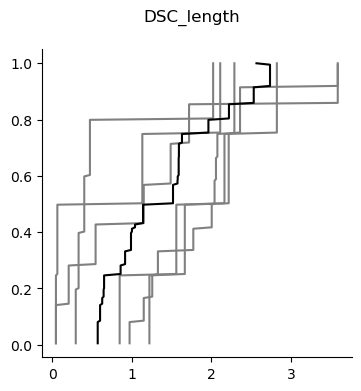

In [14]:
#select property to plot [mean, lenght, distance]
parameter='length'
df= summary_dsc(DGdata, parameter)

# plot the cumulative histogram for each dendrite
n_bins=200
n, bins, patches = plt.hist(df.transpose(), n_bins, density=True, histtype='step', cumulative=True)
# Close the plot to suppress it
plt.close()

avg_df, bins = avgCDF(df, patches, n_bins, n)

fig, ax = plt.subplots(figsize=(4, 4))
fig.suptitle("DSC_"+parameter)
ax.plot(avg_df.iloc[:, :-1], bins, color='grey')
ax.plot(avg_df.iloc[:, len(avg_df.columns)-1], bins, color='black')

#ax.set_xlim([0,500])


Fig 1j Compartment length

(0.0, 50.0)

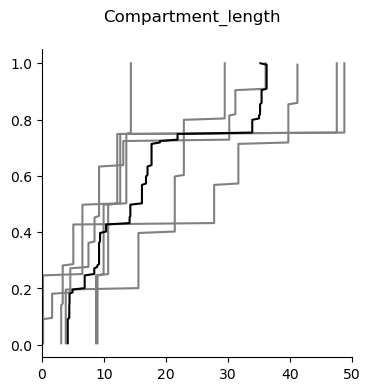

In [15]:
df= summary_compt(DGdata, 'length')

# plot the cumulative histogram for each dendrite
n_bins=200
n, bins, patches = plt.hist(df.transpose(), n_bins, density=True, histtype='step', cumulative=True)
# Close the plot to suppress it
plt.close()

avg_df, bins = avgCDF(df, patches, n_bins, n)

fig, ax = plt.subplots(figsize=(4, 4))
fig.suptitle("Compartment_length")
ax.plot(avg_df.iloc[:, :-1], bins, color='grey')
ax.plot(avg_df.iloc[:, len(avg_df.columns)-1], bins, color='black')

ax.set_xlim([0,50])

Select dendrite and branch to analyse

In [16]:
from Branch_analysis import resistances

dendbranch_dic={'dendrite1': [1,2],'dendrite3':[1,2,3], 'dendrite4':[2], 'C1_02_cell1_d2':[3], 'C1_03_cell2_d2':[5],'C1_03_cell2_d3':[3]}

for dend, branchs in dendbranch_dic.items():
    #print(dend)
    for b in branchs:
        #print(b)
        resistances(dend, b, DGdata)


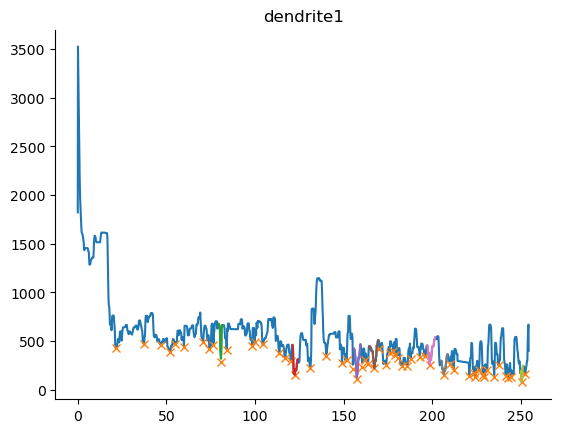

In [17]:
dend_name= 'dendrite1'  #'dendrite3' #'dendrite1' #'C1_03_cell2_d2' #'C1_02_cell1_d2' 'C1_03_cell2_d3'
#branchs=dendbranch_dic[dend_name]

fig, ax = plot_dsc(DGdata[dend_name],dend_name, corr=1)

In [18]:
df=DGdata[dend_name]['branch_info']

In [19]:
#sets start and end points of branch
branchNo=  5
strt = DGdata[dend_name]['branchNo'][branchNo][1]

if branchNo + 1 < len(DGdata[dend_name]['branchNo']) and DGdata[dend_name]['branchNo'][branchNo+1] in DGdata[dend_name]['branchNo']:
    end = DGdata[dend_name]['branchNo'][branchNo+1][1]
else:
    end = (DGdata[dend_name]['data']['length'].iloc[-1] * 
           DGdata[dend_name]['res'] / 
           DGdata[dend_name]['ex_factor'])

ax.set_xlim(strt, end)
#ax.set_xlim(000, 12000)

#ax.set_ylim(0, 3000)
fig

IndexError: list index out of range

In [ ]:
df=DGdata[dend_name]['branch_info']['branchs'][branchNo]
# Plot histogram
#hist, bins, _ = plt.hist(DGdata['C1_03_cell2_d3']['branch']['smth'], bins=20, color='skyblue', edgecolor='black')
hist, bins, _ = plt.hist(df['smth'], bins=20, color='skyblue', edgecolor='black')

# Bin centers
bin_centers = 0.5 * (bins[1:] + bins[:-1])

# Fit Gaussian to histogram
def gaussian(x, mu, sigma, A):
    return A * np.exp(-0.5 * ((x - mu) / sigma)**2)

popt, _ = curve_fit(gaussian, bin_centers, hist, p0=[df['smth'].mean(), df['smth'].std(), 1])

# Plot Gaussian fit
x = np.linspace(df['smth'].min(), df['smth'].max(), 100)
plt.plot(x, gaussian(x, *popt), 'k--', label='Gaussian Fit')

# Add labels and title
plt.title('Histogram with Gaussian Fit')
plt.xlabel('Value')
plt.ylabel('Frequency')

# Show plot
plt.legend()
plt.show()

In [ ]:
#df=DGdata['C1_03_cell2_d3']['branch']
m=df['smth'].median()
std = df['smth'].std()

fig, ax1 = plt.subplots()

ax1.plot(df.length, df.smth)

# Add a straight line at a certain y-value
plt.axhline(y=m-(2*std), color='r', linestyle='--', label='Threshold')
ax1.set_ylim(df.smth.min()-50, 1200)

df_zscored = (df['smth'] - m) / std

#fig, ax1 = plt.subplots()

ax2 = ax1.twinx()
ax1.plot(df.length, df.smth) 
plt.rc("axes.spines", top=False, right=True)
ax2.plot(df.length, df_zscored) 
ax2.set_ylim((ax1.get_ylim()[0] - m) / std, (ax1.get_ylim()[1] - m) / std)

fig.savefig(plot_path +'/C1_branch_d3_zscore.svg', bbox_inches = 'tight', format='svg')


In [52]:
#compile all resistance data 
Rmorph_data={}
length_data={}
Rdend_data={}
#Rmorph_data['dendrite3'] = []  # Initialize a list for each new key

for dendrite, d in DGdata.items():
    #print(dendrite)
    for b in d['DSC_properties']:
        #print(b)
        if 'Rmorph' in b:
            #print(dsc)
            #print(b['Rmorph'])
            if dendrite not in Rmorph_data:
                Rmorph_data[dendrite] = []  # Initialize a list for each new key
                length_data[dendrite] = []
            Rmorph_data[dendrite].append(b['Rmorph'])
            length_data[dendrite].append(b['length'])
    if 'Rdend' in d['branch_info']:
        Rdend_data[dendrite]=pd.DataFrame(d['branch_info']['Rdend'], columns=['resistance'])

Dend resisitance per micron resistance    5.54684
dtype: float64 SEM resistance    1.914526
dtype: float64 count resistance    6
dtype: int64
DSC resisitance per mircon resistance    33.797429
dtype: float64 SEM resistance    5.781561
dtype: float64 count dendrite      36
resistance    36
dtype: int64


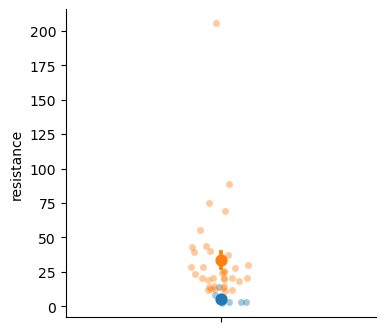

In [53]:
df = pd.concat(Rdend_data)
df = df.reset_index(level=0)
df = df.rename(columns={'level_0': 'dendrite'})

grp_df = df.groupby('dendrite').mean(numeric_only=True)

fig, ax =plt.subplots(figsize=(4, 4))
ax=sns.stripplot(y='resistance', alpha=0.4, data=grp_df)
ax=sns.pointplot(y='resistance', linestyle='none', errorbar='se',data=grp_df)

print(f"Dend resisitance per micron {grp_df.mean(numeric_only=True)} SEM {grp_df.sem(numeric_only=True)} count {grp_df.count()}")

# DSC data for the DataFrame
df_data = [(key, value) for key, values in Rmorph_data.items() for value in values]
length_data=[(key, value) for key, values in length_data.items() for value in values]
# Create the DataFrame
df = pd.DataFrame(df_data, columns=['dendrite', 'resistance'])
length_df = pd.DataFrame(length_data, columns=['dendrite', 'length'])

ax=sns.stripplot(y='resistance', alpha=0.4, data=df)
ax=sns.pointplot(y='resistance', linestyle='none', errorbar='se',data=df)

print(f"DSC resisitance per mircon {df.mean(numeric_only=True)} SEM {df.sem(numeric_only=True)} count {df.count()}")

resis = length_df.length*df.resistance
#df_data = [(key, value) for key, values in resis.items() for value in values]

# grp_df = df.groupby('dendrite').sum(numeric_only=True)
# print(f"Sum DSC resisitance per dendrite {grp_df.mean(numeric_only=True)} SEM {grp_df.sem(numeric_only=True)} count {grp_df.count()}")


0       4.030966
1     119.122449
2      38.377764
3      71.635913
4      32.102081
5       4.104745
6     115.356071
7      48.301049
8      48.301049
9      44.466236
10     50.774312
11     88.367682
12     48.394306
13    157.460911
14     39.902511
15     73.741360
16     23.501192
17     81.251762
18    110.607014
19     34.111629
20     25.434248
21     26.282290
22     17.386129
23     27.462358
24     11.497017
25     44.444191
26     91.746807
27      1.089363
28     31.250640
29     23.094126
30      2.179380
31      5.031979
32      5.496565
33      4.144494
34     17.782078
35     29.861092
dtype: float64

In [ ]:
from statistics import mean
avg_dsc = []

for k, v in dataSet.items():
    print(k)
    dsc_ls=[]
    comp_ls=[]
    for k in v['DSC_properties']:
        dsc_ls.append(k['minimum'])

    for k in v['compt_properties']:
        comp_ls.append(k['mean'])
    avg2=mean(np.array(dsc_ls))/mean(np.array(comp_ls))
    avg_dsc.append(avg2)

avg_dsc=pd.DataFrame(avg_dsc)

print(f"mean: {avg_dsc[0].mean()}, sem: {avg_dsc[0].sem()}")